In [1]:
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology
from skimage import measure
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from scipy.stats import gaussian_kde
from matplotlib.patches import FancyArrowPatch
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates
import seaborn as sns
from scipy.ndimage import maximum_filter, label
from scipy.stats import skewnorm
from scipy.stats import lognorm
from collections import deque
import fifpy

In [2]:
#Defining all the required functions

#Fourier Transform Functions
def partial_x_fft(f, dx):
    nx, ny = f.shape
    kx = 2 * np.pi * np.fft.fftfreq(nx, d=dx)
    f_fft = np.fft.fft(f, axis=0)
    df_fft = 1j * kx[:, None] * f_fft
    return np.real(np.fft.ifft(df_fft, axis=0))

def partial_y_fft(f, dy):
    nx, ny = f.shape
    ky = 2 * np.pi * np.fft.fftfreq(ny, d=dy)
    f_fft = np.fft.fft(f, axis=1)
    df_fft = 1j * ky[None, :] * f_fft
    return np.real(np.fft.ifft(df_fft, axis=1))

#Defining constants
h = 0.0625

In [3]:
#Denoising the data
def gaussian_fft_filter_2d(J_squared, k0):
    """
    Apply a Gaussian low-pass filter in Fourier space to a 2D field.

    Parameters
    ----------
    J_squared : 2D numpy array
        Input real-space data
    k0 : float
        Filter width in k-space (grid units). Smaller = stronger smoothing.

    Returns
    -------
    J_filtered : 2D numpy array
        Smoothed real-space data
    """

    # FFT
    F = np.fft.fft2(J_squared)
    F_shifted = np.fft.fftshift(F)

    # k-grid
    nx, ny = J_squared.shape
    kx = np.fft.fftshift(np.fft.fftfreq(nx)) * nx
    ky = np.fft.fftshift(np.fft.fftfreq(ny)) * ny
    KX, KY = np.meshgrid(kx, ky, indexing='ij')
    K2 = KX**2 + KY**2

    # Gaussian filter in k-space
    gaussian = np.exp(-K2 / (2 * k0**2))

    # Apply filter
    F_filt = F_shifted * gaussian

    # Inverse FFT
    F_filt = np.fft.ifftshift(F_filt)
    J_filtered = np.fft.ifft2(F_filt)

    # Return real part
    return np.real(J_filtered)

def iterative_filtering(field,index):
    fif = fifpy.MIF(NIMFs=4,alpha=30,Xi=2.0)
    fif.run(field)
    print(fif.IMC.shape)
    filtered_signal = np.sum(fif.IMC[index:],axis=0)
    return filtered_signal

def iterative_filtering(field,index,Xi=1.6):
    fif = fifpy.MIF(NIMFs=4,alpha=30,Xi=Xi)
    fif.run(field)
    print(fif.IMC.shape)
    filtered_signal = np.sum(fif.IMC[index:],axis=0)
    return filtered_signal

In [19]:
#Lets Computer J_total

# # 1. Read the HDF5 file
File_Bx = '/home/UNN/w24021992/NAS/simulations_beta_scan/beta_p_16/beta_e_1/Bx_ApJ_t40.h5'  # Replace with your file path
File_By = '/home/UNN/w24021992/NAS/simulations_beta_scan/beta_p_16/beta_e_1/By_ApJ_t40.h5'  # Replace with your file path
File_Bz = '/home/UNN/w24021992/NAS/simulations_beta_scan/beta_p_16/beta_e_1/Bz_ApJ_t40.h5'  # Replace with your file path

with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy, h5py.File(File_Bz, 'r') as fBz:
    data_Bx = fBx['DS1'][:].T
    data_By = fBy['DS1'][:].T
    data_Bz = fBz['DS1'][:].T
    # data_Bx_filtered = gaussian_fft_filter_2d(data_Bx, k0=0.1 * len(data_Bx))
    # data_By_filtered = gaussian_fft_filter_2d(data_By, k0=0.1 * len(data_Bx))
    # data_Bz_filtered = gaussian_fft_filter_2d(data_Bz, k0=0.1 * len(data_Bx))
    # data_Jx = partial_y_fft(data_Bz_filtered,h)
    # data_Jy = -partial_x_fft(data_Bz_filtered,h)
    # data_Jz = partial_x_fft(data_By_filtered,h)-partial_y_fft(data_Bx_filtered,h)
    # data_Bx = iterative_filtering(data_Bx,3,Xi=2.0)
    # data_By = iterative_filtering(data_By,3,Xi=2.0)
    # data_Bz = iterative_filtering(data_Bz,3,Xi=2.0)
    data_Jx = partial_y_fft(data_Bz,h)
    data_Jy = -partial_x_fft(data_Bz,h)
    data_Jz = partial_x_fft(data_By,h)-partial_y_fft(data_Bx,h)
    

J_squared = data_Jx**2 + data_Jy**2 + data_Jz**2
# J_squared = gaussian_fft_filter_2d(J_squared, k0=0.1 * len(data_Bx))


#Different Strategies for Threshold
#Strategy 1: Pick top 10% of the features
threshold = np.quantile(J_squared, 0.8)

#Strategy 2: 
# N = 3
# J_squared_rms = np.sqrt(np.mean(J_squared**2))
# threshold = np.mean(J_squared) + N*J_squared_rms

print("Threshold:", threshold)

binary_mask = np.abs(J_squared) > threshold


#MORPHOLOGICAL SMOOTHING
struct = morphology.disk(5)

smoothed_mask = morphology.binary_opening(binary_mask, struct)
smoothed_mask = morphology.binary_closing(smoothed_mask, struct)
smoothed_mask = smoothed_mask.astype(int)

#Remove small areas
min_area = 300 # choose based on eye balling
cleaned_mask = morphology.remove_small_objects(smoothed_mask.astype(bool), min_size=min_area).astype(int)

Threshold: 0.31441029386642516


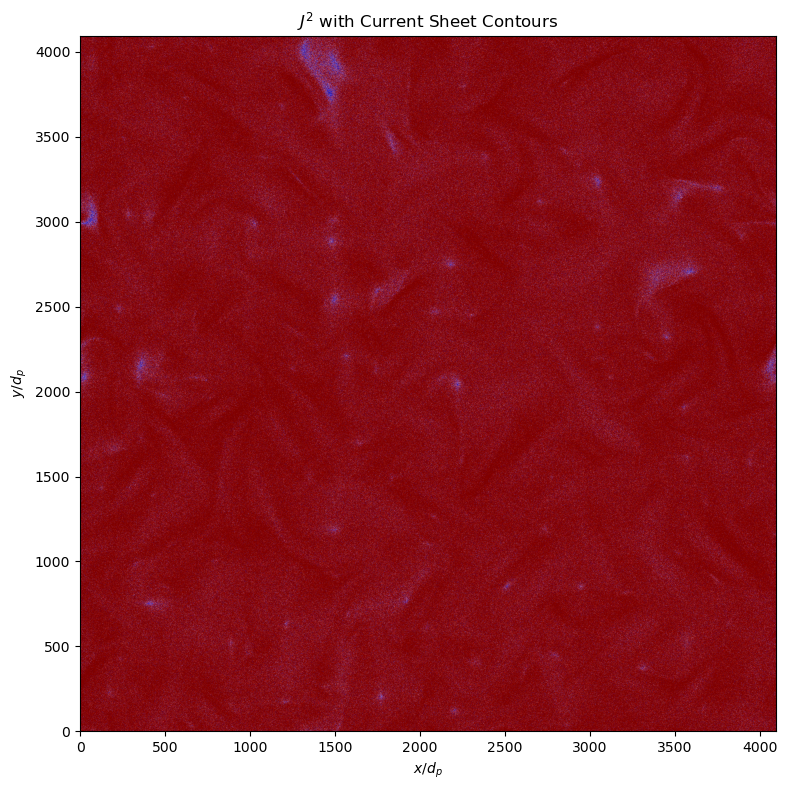

In [20]:
#Plot current sheets over the base J_squared field

plt.figure(figsize=(10, 8))

# Base field
plt.imshow(J_squared.T, cmap='seismic', origin='lower', vmax=0.05)

# Add current-sheet boundaries
plt.contour(cleaned_mask.T, levels=[0.5], colors='yellow', linewidths=1)

plt.title(r'$J^{2}$ with Current Sheet Contours')
plt.xlabel(r'$x/d_p$')
plt.ylabel(r'$y/d_p$')
plt.tight_layout()
plt.savefig("J2_NR_with_CS_contours.png", dpi=300)
plt.show()

In [21]:
#FIND MAXIMUM IN EACH CONNECTED REGION

labeled_mask, num_features = label(cleaned_mask)
print("Regions found:", num_features)

max_coords = []
max_values = []

for i in range(1, num_features + 1):
    region_mask = (labeled_mask == i)
    region_vals = J_squared[region_mask]

    if region_vals.size == 0:
        continue

    # Extreme value (max magnitude)
    max_pos = np.argmax(np.abs(region_vals))
    extreme_value = region_vals[max_pos]
    max_values.append(extreme_value)

    # Convert index → coordinates
    xs, ys = np.where(region_mask)
    max_coords.append((xs[max_pos], ys[max_pos]))

Regions found: 0


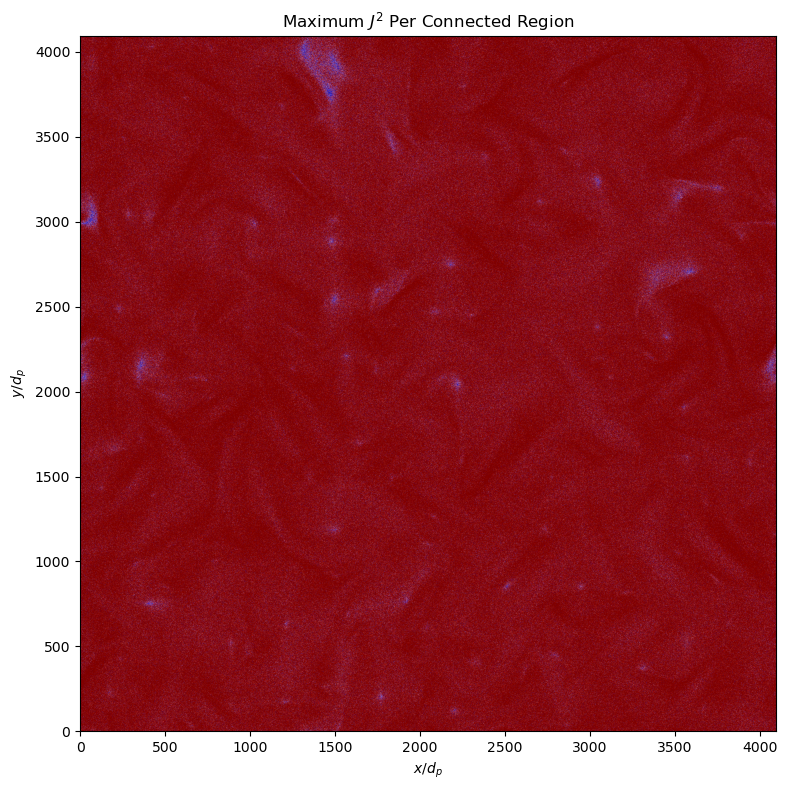

In [22]:
# PLOT ORIGINAL FIELD + MASK + MAXIMUM POINTS

plt.figure(figsize=(10, 8))

# --- Base field ---
plt.imshow(J_squared.T, cmap='seismic', origin='lower', vmax=0.05)

# --- Boundaries of CSs---
boundaries = find_boundaries(labeled_mask)
plt.contour(boundaries.T, levels=[0.5], colors='white', linewidths=1)

# --- Overlay maxima as yellow crosses ---
for x, y in max_coords:
    plt.plot(x, y, marker='x', markersize=10, markeredgewidth=1.5, color='yellow')

plt.title(r'Maximum $J^{2}$ Per Connected Region')
plt.xlabel(r'$x/d_p$')
plt.ylabel(r'$y/d_p$')

plt.tight_layout()
plt.savefig("J2_NR_maxima_overlay.png", dpi=300)
plt.show()

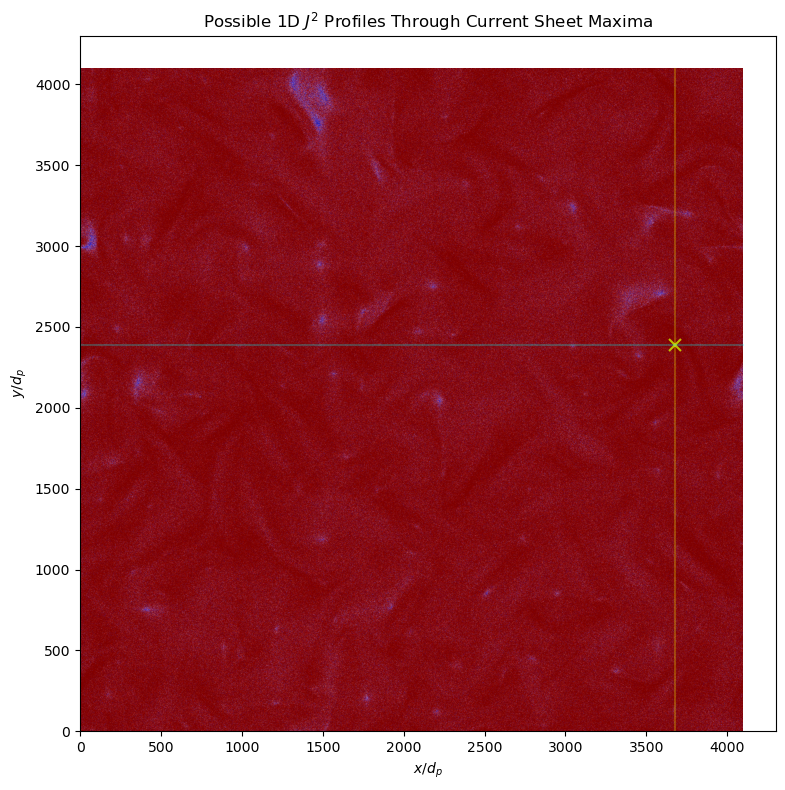

In [23]:
# Convert tuple list if needed
coords = [
 (3680, 2388)
]

plt.figure(figsize=(10,8))

# Base J^2 field
plt.imshow(J_squared.T, cmap='seismic', origin='lower', vmax=0.05)

# Current sheet boundaries
boundaries = find_boundaries(labeled_mask)
plt.contour(boundaries.T, levels=[0.5], colors='white', linewidths=1)

nx, ny = J_squared.shape

for x, y in coords:
    
    # mark maxima
    plt.plot(x, y, 'yx', markersize=8, markeredgewidth=1.5)

    # vertical cut
    plt.plot([x, x], [0, ny], color='yellow', alpha=0.25)

    # horizontal cut
    plt.plot([0, nx], [y, y], color='cyan', alpha=0.25)

plt.title(r'Possible 1D $J^2$ Profiles Through Current Sheet Maxima')
plt.xlabel(r'$x/d_p$')
plt.ylabel(r'$y/d_p$')
plt.savefig("J2_CS_Selection.png", dpi=300)
plt.tight_layout()
plt.show()

In [24]:
# compute gradients
grad_x, grad_y = np.gradient(J_squared)

# point of interest
x0, y0 = 3680, 2388

# gradient at the maximum
gx = grad_x[x0, y0]
gy = grad_y[x0, y0]

# direction of steepest descent
direction = np.array([-gx, -gy])

# normalize
direction = direction / np.linalg.norm(direction)

dx, dy = direction

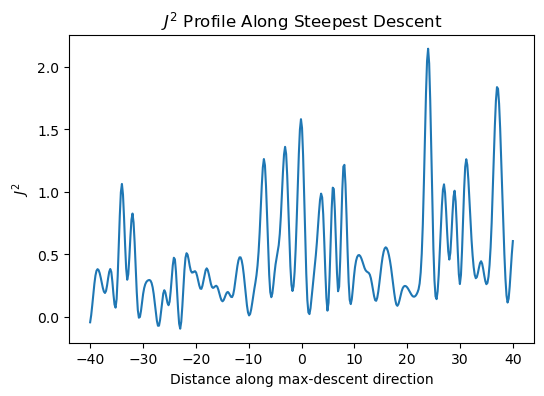

In [25]:
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

# distance along the cut
L = 40
s = np.linspace(-L, L, 400)

# coordinates along the line
x_line = x0 + s*dx
y_line = y0 + s*dy

# interpolate J^2 along the line
profile = map_coordinates(J_squared, [x_line, y_line], order=3)

plt.figure(figsize=(6,4))
plt.plot(s, profile)
# plt.axvline(0, linestyle='--')
plt.xlabel('Distance along max-descent direction')
plt.ylabel(r'$J^2$')
plt.title(r'$J^2$ Profile Along Steepest Descent')
plt.savefig("J2_1D_Cut_NoFilter.png", dpi=300)
plt.show()

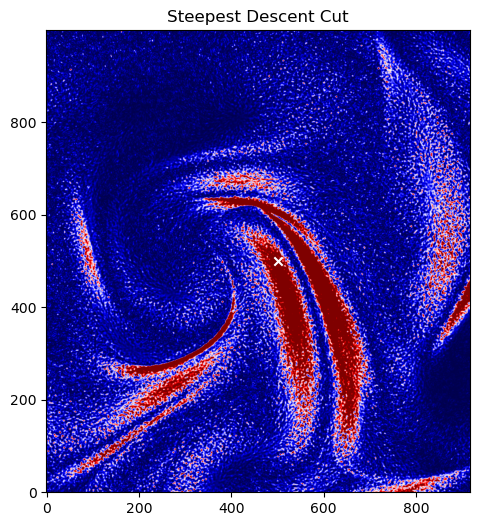

In [14]:
window = 500

plt.figure(figsize=(6,6))

plt.imshow(
    J_squared[x0-window:x0+window, y0-window:y0+window].T,
    cmap='seismic',
    origin='lower', vmax=0.05
)

# shift coordinates to local frame
x_local = x_line - (x0-window)
y_local = y_line - (y0-window)

# plt.plot(x_local, y_local, color='yellow', linewidth=2)
plt.scatter(window, window, color='white', marker='x')

plt.title(r'Steepest Descent Cut')
plt.savefig("J2_1D_Cut_Steepest_Decent_NoFilter.png", dpi=300)
plt.show()

In [15]:
x0, y0 = 3680, 2388

# region ID containing this maximum
region_id = labeled_mask[x0, y0]

region = (labeled_mask == region_id)

In [16]:
dist = ndi.distance_transform_edt(region)

radius = dist.max()
thickness_m1 = 2 * radius

# center of largest inscribed circle
cx, cy = np.unravel_index(np.argmax(dist), dist.shape)

print("Thickness (Method 1) =", thickness_m1, "pixels")
print("Circle center =", (cx, cy))

Thickness (Method 1) = 77.20103626247513 pixels
Circle center = (np.int64(3716), np.int64(2242))


In [17]:
x0, y0 = 3680, 2388
dx, dy = direction

x, y = float(x0), float(y0)
step_size = 1
max_steps = 1000

# --- forward ---
xf, yf = x, y
for _ in range(max_steps):

    xf_new = xf + dx*step_size
    yf_new = yf + dy*step_size

    xi, yi = int(round(xf_new)), int(round(yf_new))

    if xi < 0 or yi < 0 or xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]:
        break

    if not cleaned_mask[xi, yi]:
        break

    xf, yf = xf_new, yf_new

dist_forward = np.hypot(xf-x, yf-y)

# --- backward ---
xb, yb = x, y
for _ in range(max_steps):

    xb_new = xb - dx*step_size
    yb_new = yb - dy*step_size

    xi, yi = int(round(xb_new)), int(round(yb_new))

    if xi < 0 or yi < 0 or xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]:
        break

    if not cleaned_mask[xi, yi]:
        break

    xb, yb = xb_new, yb_new

dist_backward = np.hypot(xb-x, yb-y)

thickness_m2 = dist_forward + dist_backward

print("Forward distance:", dist_forward)
print("Backward distance:", dist_backward)
print("Thickness (Method 2):", thickness_m2)

Forward distance: 35.99999999999955
Backward distance: 25.99999999999968
Thickness (Method 2): 61.99999999999923


In [18]:
# Gaussian model
def gaussian(t, A, mu, sigma, B):
    return A * np.exp(-(t - mu)**2 / (2*sigma**2)) + B

# maximum location
x0, y0 = 3680, 2388

# descent direction computed previously
dx, dy = dx, dy  # from your steepest descent computation

# parameters
max_len = 60  # half-length of profile
step_px = 1

# sample profile along steepest descent
xs = []
vals = []

for k in range(-max_len, max_len + 1):
    xc = x0 + k*dx
    yc = y0 + k*dy
    xi = int(round(xc))
    yi = int(round(yc))

    if 0 <= xi < J_squared.shape[0] and 0 <= yi < J_squared.shape[1]:
        xs.append(k)
        vals.append(J_squared[xi, yi])

xs = np.array(xs)
vals = np.array(vals)

# initial guess for Gaussian
A0 = vals.max() - vals.min()
mu0 = xs[np.argmax(vals)]
sigma0 = max_len/4
B0 = vals.min()

# fit Gaussian
popt, pcov = curve_fit(gaussian, xs, vals, p0=[A0, mu0, sigma0, B0])
A, mu, sigma, B = popt
fwhm = 2 * np.sqrt(2*np.log(2)) * sigma

print("Method 3 FWHM thickness:", fwhm, "pixels")
thickness_m3 = fwhm

Method 3 FWHM thickness: 21.792828700651878 pixels


Y value at FWHM: 0.087


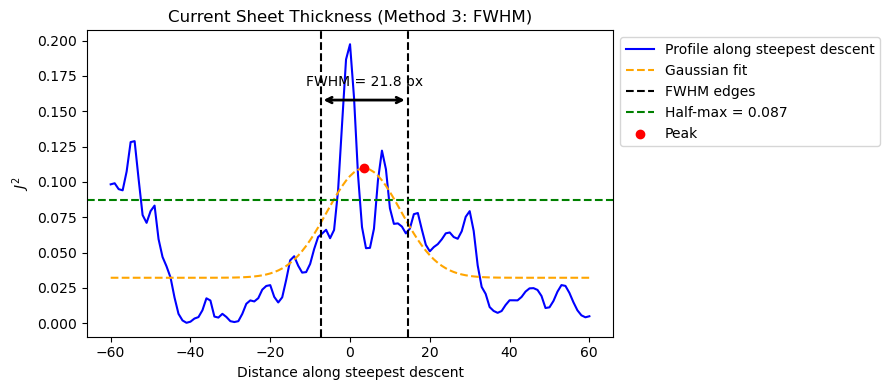

In [19]:
import matplotlib.pyplot as plt
import numpy as np

# Gaussian fit values
fit_vals = gaussian(xs, *popt)

# FWHM edges
left = mu - fwhm/2
right = mu + fwhm/2

# Y-value at half maximum
y_half = gaussian(mu, *popt)/2 + popt[3]  # A/2 + B
print(f"Y value at FWHM: {y_half:.3f}")

plt.figure(figsize=(9, 4))
plt.plot(xs, vals, label="Profile along steepest descent", color='blue')
plt.plot(xs, fit_vals, '--', label="Gaussian fit", color='orange')

# Vertical lines at FWHM edges
plt.axvline(left, linestyle='--', color='black', label='FWHM edges')
plt.axvline(right, linestyle='--', color='black')

# Horizontal line at half maximum
plt.axhline(y_half, linestyle='--', color='green', label=f'Half-max = {y_half:.3f}')

# Peak marker
plt.scatter(mu, gaussian(mu,*popt), color='red', zorder=3, label='Peak')

# Arrow showing FWHM
plt.annotate(
    "",
    xy=(right, max(vals)*0.8),
    xytext=(left, max(vals)*0.8),
    arrowprops=dict(arrowstyle="<->", color='black', linewidth=2)
)
plt.text(mu, max(vals)*0.85, f"FWHM = {fwhm:.1f} px", ha='center', color='black')

plt.xlabel("Distance along steepest descent")
plt.ylabel(r"$J^2$")
plt.title("Current Sheet Thickness (Method 3: FWHM)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig("J2_FWHM.png", dpi=300)
plt.show()

In [20]:
# Maximum location
x0, y0 = 3680, 2388

# Threshold for region growth
J2_thresh_region = 0.005 * np.max(J_squared)

# Initialize empty mask
cs_mask = np.zeros_like(J_squared, dtype=bool)

# Queue for BFS
queue = deque()
queue.append((x0, y0))

# Keep track of visited pixels
visited = np.zeros_like(J_squared, dtype=bool)

# Directions for 4-neighbors (up, down, left, right)
neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]

# Flood-fill / grow the region
while queue:
    x, y = queue.popleft()
    if visited[x, y]:
        continue
    visited[x, y] = True

    # Check threshold
    if J_squared[x, y] >= J2_thresh_region:
        cs_mask[x, y] = True

        # Add 4-neighbors to queue
        for dx, dy in neighbors:
            xn, yn = x + dx, y + dy
            if 0 <= xn < J_squared.shape[0] and 0 <= yn < J_squared.shape[1]:
                if not visited[xn, yn]:
                    queue.append((xn, yn))

# Optional: smooth mask slightly
from skimage import morphology
cs_mask = morphology.binary_opening(cs_mask, morphology.disk(5))
cs_mask = morphology.binary_closing(cs_mask, morphology.disk(5))

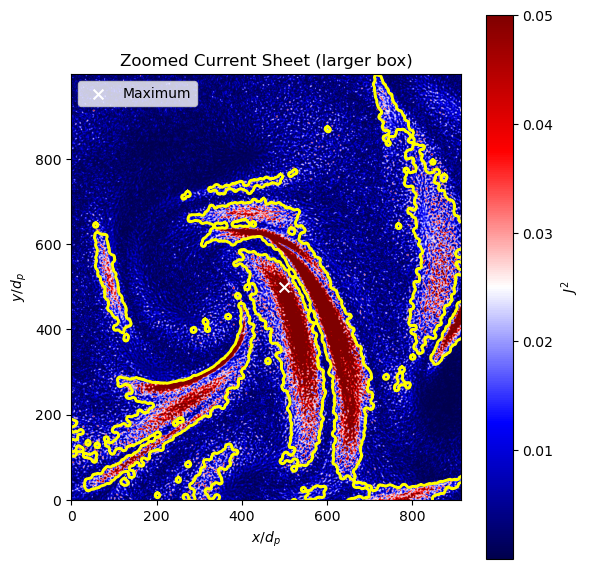

In [21]:
# Zoom box size
half_box = 500  # pixels around the CS bounding box center

# Center of CS
x_center = x0
y_center = y0

# Compute zoom limits
x_min = max(x_center - half_box, 0)
x_max = min(x_center + half_box, J_squared.shape[0])
y_min = max(y_center - half_box, 0)
y_max = min(y_center + half_box, J_squared.shape[1])

# Plot zoomed-in view
plt.figure(figsize=(6,6))
plt.imshow(J_squared.T[y_min:y_max, x_min:x_max], cmap='seismic', origin='lower', vmax=0.05)
plt.colorbar(label=r'$J^2$')

# Overlay CS contour (shifted to zoomed frame)
zoom_mask = cs_mask.T[y_min:y_max, x_min:x_max]
contour = measure.find_contours(zoom_mask, level=0.5)
# contour = measure.find_contours(cs_mask.T, level=0.5)
for c in contour:
    plt.plot(c[:,1], c[:,0], color='yellow', linewidth=2)

# Mark maximum (shifted)
plt.scatter(y0 - y_min, x0 - x_min, color='white', marker='x', s=50, label='Maximum')

plt.title("Zoomed Current Sheet (larger box)")
plt.xlabel(r"$x/d_p$")
plt.ylabel(r"$y/d_p$")
plt.legend()
plt.tight_layout()
plt.savefig("J2_M4_Single_Sheet_Threshold.png", dpi=300)
plt.show()

In [22]:
len(contour)

48

In [23]:
x0, y0 = 3680, 2388
dx, dy = direction

x, y = float(x0), float(y0)
step_size = 1
max_steps = 1000

# --- forward ---
xf, yf = x, y
for _ in range(max_steps):

    xf_new = xf + dx*step_size
    yf_new = yf + dy*step_size

    xi, yi = int(round(xf_new)), int(round(yf_new))

    if xi < 0 or yi < 0 or xi >= cs_mask.shape[0] or yi >= cs_mask.shape[1]:
        break

    if not cs_mask[xi, yi]:
        break

    xf, yf = xf_new, yf_new

dist_forward = np.hypot(xf-x, yf-y)

# --- backward ---
xb, yb = x, y
for _ in range(max_steps):

    xb_new = xb - dx*step_size
    yb_new = yb - dy*step_size

    xi, yi = int(round(xb_new)), int(round(yb_new))

    if xi < 0 or yi < 0 or xi >= cs_mask.shape[0] or yi >= cs_mask.shape[1]:
        break

    if not cs_mask[xi, yi]:
        break

    xb, yb = xb_new, yb_new

dist_backward = np.hypot(xb-x, yb-y)

thickness_m4 = dist_forward + dist_backward

print("Forward distance:", dist_forward)
print("Backward distance:", dist_backward)
print("Thickness (Method 4):", thickness_m4)

Forward distance: 65.99999999999919
Backward distance: 26.999999999999666
Thickness (Method 4): 92.99999999999886


In [24]:
# Maximum location
x0, y0 = 3680, 2388

# Threshold for region growth
J2_thresh_region_m5 = 0.1 * J_squared[3732, 2228]

# Initialize empty mask
cs_mask = np.zeros_like(J_squared, dtype=bool)

# Queue for BFS
queue = deque()
queue.append((x0, y0))

# Keep track of visited pixels
visited = np.zeros_like(J_squared, dtype=bool)

# Directions for 4-neighbors (up, down, left, right)
neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]

# Flood-fill / grow the region
while queue:
    x, y = queue.popleft()
    if visited[x, y]:
        continue
    visited[x, y] = True

    # Check threshold
    if J_squared[x, y] >= J2_thresh_region_m5:
        cs_mask[x, y] = True

        # Add 4-neighbors to queue
        for dx, dy in neighbors:
            xn, yn = x + dx, y + dy
            if 0 <= xn < J_squared.shape[0] and 0 <= yn < J_squared.shape[1]:
                if not visited[xn, yn]:
                    queue.append((xn, yn))

# Optional: smooth mask slightly
from skimage import morphology
cs_mask = morphology.binary_opening(cs_mask, morphology.disk(5))
cs_mask = morphology.binary_closing(cs_mask, morphology.disk(5))

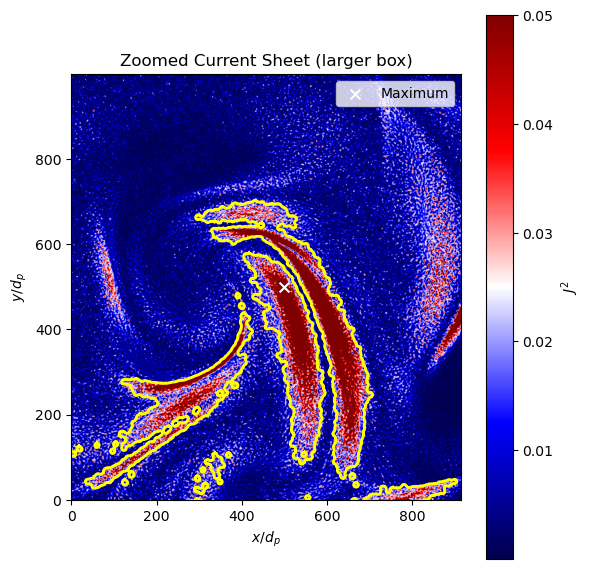

In [25]:
# Zoom box size
half_box = 500  # pixels around the CS bounding box center

# Center of CS
x_center = x0
y_center = y0

# Compute zoom limits
x_min = max(x_center - half_box, 0)
x_max = min(x_center + half_box, J_squared.shape[0])
y_min = max(y_center - half_box, 0)
y_max = min(y_center + half_box, J_squared.shape[1])

# Plot zoomed-in view
plt.figure(figsize=(6,6))
plt.imshow(J_squared.T[y_min:y_max, x_min:x_max], cmap='seismic', origin='lower', vmax=0.05)
plt.colorbar(label=r'$J^2$')

# Overlay CS contour (shifted to zoomed frame)
zoom_mask = cs_mask.T[y_min:y_max, x_min:x_max]
contour = measure.find_contours(zoom_mask, level=0.5)
# contour = measure.find_contours(cs_mask.T, level=0.5)
for c in contour:
    plt.plot(c[:,1], c[:,0], color='yellow', linewidth=2)

# Mark maximum (shifted)
plt.scatter(y0 - y_min, x0 - x_min, color='white', marker='x', s=50, label='Maximum')

plt.title("Zoomed Current Sheet (larger box)")
plt.xlabel(r"$x/d_p$")
plt.ylabel(r"$y/d_p$")
plt.legend()
plt.tight_layout()
plt.savefig("J2_M5_Single_Sheet_Threshold.png", dpi=300)
plt.show()

In [26]:
x0, y0 = 3680,2388
dx, dy = direction

x, y = float(x0), float(y0)
step_size = 1
max_steps = 1000

# --- forward ---
xf, yf = x, y
for _ in range(max_steps):

    xf_new = xf + dx*step_size
    yf_new = yf + dy*step_size

    xi, yi = int(round(xf_new)), int(round(yf_new))

    if xi < 0 or yi < 0 or xi >= cs_mask.shape[0] or yi >= cs_mask.shape[1]:
        break

    if not cs_mask[xi, yi]:
        break

    xf, yf = xf_new, yf_new

dist_forward = np.hypot(xf-x, yf-y)

# --- backward ---
xb, yb = x, y
for _ in range(max_steps):

    xb_new = xb - dx*step_size
    yb_new = yb - dy*step_size

    xi, yi = int(round(xb_new)), int(round(yb_new))

    if xi < 0 or yi < 0 or xi >= cs_mask.shape[0] or yi >= cs_mask.shape[1]:
        break

    if not cs_mask[xi, yi]:
        break

    xb, yb = xb_new, yb_new

dist_backward = np.hypot(xb-x, yb-y)

thickness_m5 = dist_forward + dist_backward

print("Forward distance:", dist_forward)
print("Backward distance:", dist_backward)
print("Thickness (Method 5):", thickness_m5)

Forward distance: 56.9999999999993
Backward distance: 26.999999999999666
Thickness (Method 5): 83.99999999999896


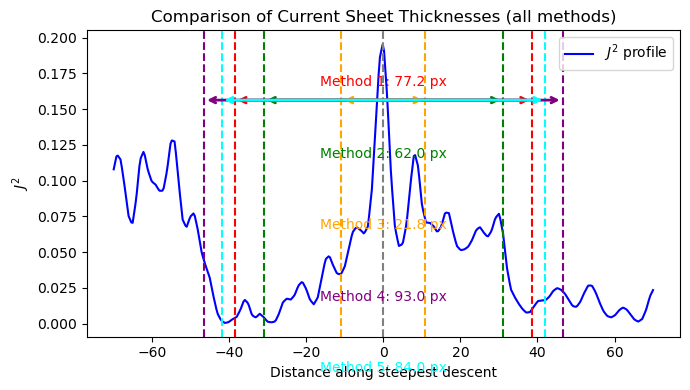

In [27]:
# Distance along the line
L = 70
s = np.linspace(-L, L, 400)

# Coordinates along the steepest descent
x_line = x0 + s*dx
y_line = y0 + s*dy

# Interpolate J^2 along the line
profile = map_coordinates(J_squared, [x_line, y_line], order=1)

plt.figure(figsize=(7,4))
plt.plot(s, profile, label=r"$J^2$ profile", color='blue')
plt.axvline(0, linestyle='--', color='gray')

# --- Overlay thicknesses ---
methods = {
    'Method 1': thickness_m1,
    'Method 2': thickness_m2,
    'Method 3': thickness_m3,
    'Method 4': thickness_m4,
    'Method 5': thickness_m5
}

colors = ['red', 'green', 'orange', 'purple', 'cyan']

for (name, thick), color in zip(methods.items(), colors):
    half = thick / 2
    plt.axvline(-half, linestyle='--', color=color)
    plt.axvline(half, linestyle='--', color=color)
    plt.annotate(
        "",
        xy=(half, profile.max()*0.8),
        xytext=(-half, profile.max()*0.8),
        arrowprops=dict(arrowstyle="<->", color=color, linewidth=2)
    )
    plt.text(0, profile.max()*0.85 - 0.05*list(methods.keys()).index(name),
             f"{name}: {thick:.1f} px",
             color=color, ha='center')

plt.xlabel("Distance along steepest descent")
plt.ylabel(r"$J^2$")
plt.title("Comparison of Current Sheet Thicknesses (all methods)")
plt.legend()
plt.tight_layout()
plt.show()

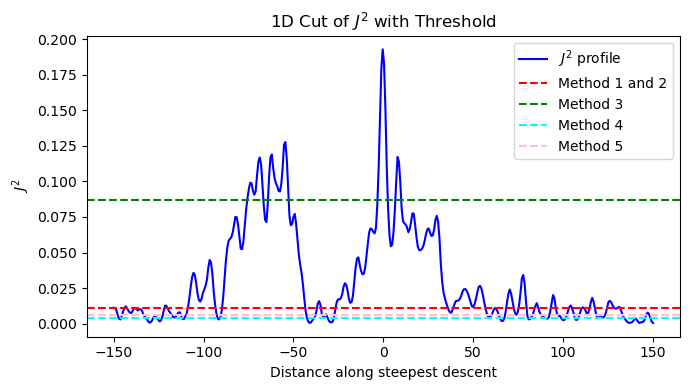

In [29]:
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates
import numpy as np

# Distance along the cut
L = 150
s = np.linspace(-L, L, 400)

# Coordinates along the steepest descent
x_line = x0 + s*dx
y_line = y0 + s*dy

# Interpolate J^2 along the line
profile = map_coordinates(J_squared, [x_line, y_line], order=1)

plt.figure(figsize=(7,4))
plt.plot(s, profile, label=r"$J^2$ profile", color='blue')

# Vertical line at threshold
plt.axhline(threshold, color='red', linestyle='--', label='Method 1 and 2')
plt.axhline(y_half, color='green', linestyle='--', label='Method 3')
plt.axhline(J2_thresh_region, color='cyan', linestyle='--', label='Method 4')
plt.axhline(J2_thresh_region_m5, color='pink', linestyle='--', label='Method 5')



plt.xlabel("Distance along steepest descent")
plt.ylabel(r"$J^2$")
plt.title("1D Cut of $J^2$ with Threshold")
plt.legend()
plt.tight_layout()
plt.savefig("J2_Threshold_Comparison.png", dpi=300)
plt.show()